# Clasificación de la severidad en tres bandas: barato, intermedio, caro

Versión análoga al Notebook 04 (modelado de frecuencia y severidad), aplicada a la clasificación
ordinal de la severidad media por siniestro en tres bandas.

**Decisiones de diseño**
- **Datos:** `freMTPL2freq.csv` + `freMTPL2sev.csv`, igual que el 04 (no `df_final.pkl`).
- **Objetivo:** severidad media por siniestro, `ClaimAmount / ClaimNb`, sólo pólizas con siniestro.
  Es la misma respuesta que el modelo de severidad del 04.
- **Predictores:** `FEATURES` de `src/modelado.py`. Se excluyen `IDpol` (identificador), `ClaimNb`
  (denominador del objetivo y peso de severidad) y `Exposure` (no entra en severidad en el 04).
- **Partición:** a nivel de póliza, estratificada por tramos de la severidad. Así las colas no quedan
  repartidas al azar entre train y test.
- **Cortes:** se estiman dentro de cada fold de validación y, para el modelo final, con todo el train.
  El test no interviene en la selección.
- **Modelos y balanceo:** GLM (regresión logística multinomial con penalización L2), XGBoost y LightGBM,
  con `sin_balanceo`, `weights`, `smote` y `adasyn`, como en el 04.

In [2]:
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import adjusted_rand_score

try:
    display
except NameError:          # ejecución como script fuera de Jupyter
    def display(x):
        print(x)

sys.path.append(str(Path("..").resolve()))
from src.utils import load_freq, load_sev
from src.modelado import preparar_datos
from src.clasificacion import (
    ETIQUETAS, EXCLUIDAS, METODOS, METODOS_PRINCIPALES, BALANCEOS, MODELOS,
    preparar_severidad, dividir_estratificado, resumen_particion,
    obtener_funciones_cortes, etiquetar, gvf, leer_checkpoints, mejores_por_metodo_modelo,
    cargar_modelo, ejecutar_experimentos, bootstrap_f1, metricas,
)

# Cortes fijos en unidades de monto (no de log). PROPUESTA a confirmar con criterio de negocio:
# barato < 1 000, intermedio 1 000–3 000, caro > 3 000. Con estos valores la banda
# barato contiene ~31 % del train y caro ~9 %. Los cortes 100 y 1 000 del borrador dejaban
# barato casi vacío, porque la mediana de la severidad es ~1 172.
CORTES_FIJOS_MONTO = (1000.0, 3000.0)

MODO_PRUEBA = False
if MODO_PRUEBA:
    CARPETA, N_CONFIGS, CV_FOLDS = "models_clasificacion_prueba", 1, 3
else:
    CARPETA, N_CONFIGS, CV_FOLDS = "models_clasificacion", 3, 3
RATIO_SOBREMUESTREO = 0.2     # minoría / mayoría tras SMOTE/ADASYN, como en el 04

## 1. Carga de datos y definición del objetivo

In [3]:
df = preparar_datos(load_freq("freMTPL2freq.csv"), load_sev("freMTPL2sev.csv"))
X, sev = preparar_severidad(df)

print(f"Pólizas con siniestro: {len(X):,}")
print("Predictores:", list(X.columns))
print("Excluidas (identificador, fuga u objetivo):", EXCLUIDAS)
print("\nSeveridad media por siniestro (monto):")
print(pd.Series(sev).describe(percentiles=[.25, .5, .75, .9, .99]).round(1).to_string())

Pólizas con siniestro: 24,938
Predictores: ['VehPower', 'VehAge', 'DrivAge', 'BonusMalus', 'Density', 'Area', 'VehBrand', 'VehGas', 'Region', 'LogDensity']
Excluidas (identificador, fuga u objetivo): ['IDpol', 'ClaimNb', 'Exposure', 'ClaimAmount']

Severidad media por siniestro (monto):
count      24938.0
mean        2221.4
std        28996.1
min            1.0
25%          709.5
50%         1172.0
75%         1226.8
90%         2737.5
99%        16328.0
max      4075400.6


## 2. Partición estratificada a nivel de póliza

Los estratos son tramos de `log1p(severidad)` entre cuantiles (0,25 / 0,5 / 0,75 / 0,9 / 0,95 / 0,99).
Se usan sólo para repartir proporcionalmente las colas entre train y test. No son predictores.

In [4]:
idx_tr, idx_te, estrato = dividir_estratificado(sev)
X_tr = X.iloc[idx_tr].reset_index(drop=True)
X_te = X.iloc[idx_te].reset_index(drop=True)
sev_tr, sev_te = sev[idx_tr], sev[idx_te]
estrato_tr = estrato[idx_tr]

n_estratos = estrato.max() + 1
print(f"Train: {len(X_tr):,} | Test: {len(X_te):,}")
print(pd.DataFrame({
    "estrato": range(n_estratos),
    "n_train": np.bincount(estrato_tr, minlength=n_estratos),
    "n_test": np.bincount(estrato[idx_te], minlength=n_estratos),
}).to_string(index=False))

Train: 19,950 | Test: 4,988
 estrato  n_train  n_test
       0     4988    1247
       1     4705    1177
       2     5269    1317
       3     2993     748
       4      997     250
       5      798     199
       6      200      50


## 3. Exploración de la severidad

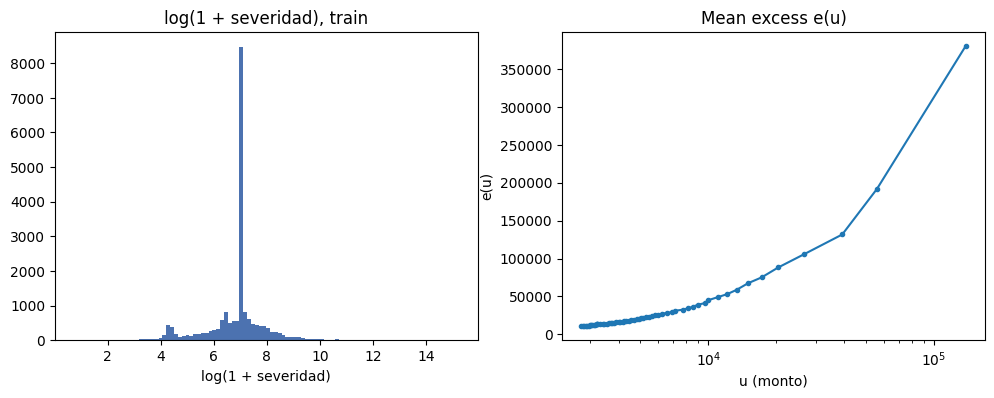

In [5]:
log_tr = np.log1p(sev_tr)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(log_tr, bins=100, color="#4C72B0")
ax[0].set_title("log(1 + severidad), train")
ax[0].set_xlabel("log(1 + severidad)")
u_grid = np.quantile(sev_tr, np.linspace(0.90, 0.999, 60))
e_u = [(sev_tr[sev_tr > u] - u).mean() if (sev_tr > u).any() else np.nan for u in u_grid]
ax[1].plot(u_grid, e_u, marker=".")
ax[1].set_xscale("log")
ax[1].set_title("Mean excess e(u)")
ax[1].set_xlabel("u (monto)")
ax[1].set_ylabel("e(u)")
Path(CARPETA).mkdir(exist_ok=True)
fig.savefig(Path(CARPETA) / "eda_severidad.png", dpi=120, bbox_inches="tight")
plt.show()

## 4. Cortes por método sobre el train completo

La regla de Wang deja aproximadamente √n observaciones en cada cola, así que las bandas barato y caro
son pequeñas. Es una propiedad del método. Por eso se revisa el conteo en test: si una banda tuviera
menos de 30 casos, la métrica de esa banda no sería confiable.

In [6]:
FUNCIONES = obtener_funciones_cortes(cortes_monto=CORTES_FIJOS_MONTO)
cortes_train = {m: FUNCIONES[m](log_tr) for m in METODOS}

tabla_bandas = resumen_particion(sev_tr, sev_te, cortes_train)
display(tabla_bandas.pivot(index="metodo", columns="banda",
                           values=["n_train", "n_test"]))

resumen_cortes = pd.DataFrame([
    {"metodo": m,
     "tipo": "principal" if m in METODOS_PRINCIPALES else "referencia",
     "cortes_monto": np.round(np.expm1(cortes_train[m]), 1).tolist(),
     "gvf_train": round(gvf(log_tr, cortes_train[m]), 4)}
    for m in METODOS
])
display(resumen_cortes)

minimo_test = tabla_bandas.groupby("metodo")["n_test"].min()
if (minimo_test < 30).any():
    print("ADVERTENCIA: alguna banda tiene menos de 30 casos en test:")
    print(minimo_test[minimo_test < 30])

/opt/miniconda3/envs/seminario-seguros/lib/python3.10/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/opt/miniconda3/envs/seminario-seguros/lib/python3.10/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: overflow encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/opt/miniconda3/envs/seminario-seguros/lib/python3.10/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: invalid value encountered in matmul
  current_pot = closest_dist_sq @ sample_weight


n_train                  n_test                
banda            barato  caro intermedio barato caro intermedio
metodo                                                         
ancho_igual_log    2283   103      17564    551   27       4410
fijos              6248  1800      11902   1545  452       2991
jenks              2646  2493      14811    661  625       3702
kmeans             2660  2491      14799    665  625       3698
regla_cola          141   142      19667     32   36       4920

,metodo,tipo,cortes_monto,gvf_train
0,jenks,principal,"[337.7, 2305.0]",0.7940
1,kmeans,principal,"[339.0, 2311.9]",0.7940
2,regla_cola,principal,"[30.2, 22567.2]",0.1967
3,ancho_igual_log,referencia,"[260.1, 32619.9]",0.6394
4,fijos,referencia,"[1000.0, 3000.0]",0.6596


ADVERTENCIA: alguna banda tiene menos de 30 casos en test:
metodo
ancho_igual_log    27
Name: n_test, dtype: int64


## 5. Entrenamiento con checkpoints

Cada combinación (método, modelo, balanceo, configuración) se guarda en `checkpoints.csv` al terminar.
Si el notebook se interrumpe, al volver a ejecutarlo se omiten las combinaciones ya guardadas.
Con `MODO_PRUEBA = True` se hace una corrida corta de validación.

In [7]:
ck = ejecutar_experimentos(
    X_tr, sev_tr, estrato_tr, X_te, sev_te, FUNCIONES,
    metodos=METODOS, modelos=MODELOS, balanceos=BALANCEOS,
    n_configs=N_CONFIGS, cv_folds=CV_FOLDS, carpeta=CARPETA,
    ratio=RATIO_SOBREMUESTREO,
)

Combinaciones totales: 180
[4/180] jenks|GLM|adasyn|cfg0 ERROR: ValueError('No samples will be generated with the provided ratio settings.')
[8/180] jenks|GLM|adasyn|cfg1 ERROR: ValueError('No samples will be generated with the provided ratio settings.')
[12/180] jenks|GLM|adasyn|cfg2 ERROR: ValueError('No samples will be generated with the provided ratio settings.')
[16/180] jenks|XGBoost|adasyn|cfg0 ERROR: ValueError('No samples will be generated with the provided ratio settings.')
[20/180] jenks|XGBoost|adasyn|cfg1 ERROR: ValueError('No samples will be generated with the provided ratio settings.')
[24/180] jenks|XGBoost|adasyn|cfg2 ERROR: ValueError('No samples will be generated with the provided ratio settings.')
[28/180] jenks|LightGBM|adasyn|cfg0 ERROR: ValueError('No samples will be generated with the provided ratio settings.')
[32/180] jenks|LightGBM|adasyn|cfg1 ERROR: ValueError('No samples will be generated with the provided ratio settings.')
[36/180] jenks|LightGBM|adasyn|cf

/opt/miniconda3/envs/seminario-seguros/lib/python3.10/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/opt/miniconda3/envs/seminario-seguros/lib/python3.10/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: overflow encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/opt/miniconda3/envs/seminario-seguros/lib/python3.10/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: invalid value encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/opt/miniconda3/envs/seminario-seguros/lib/python3.10/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/opt/miniconda3/envs/seminario-seguros/lib/python3.10/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: overflow encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/opt/min

[48/180] kmeans|GLM|adasyn|cfg2 ERROR: ValueError('No samples will be generated with the provided ratio settings.')
[52/180] kmeans|XGBoost|adasyn|cfg0 ERROR: ValueError('No samples will be generated with the provided ratio settings.')
[56/180] kmeans|XGBoost|adasyn|cfg1 ERROR: ValueError('No samples will be generated with the provided ratio settings.')


/opt/miniconda3/envs/seminario-seguros/lib/python3.10/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/opt/miniconda3/envs/seminario-seguros/lib/python3.10/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: overflow encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/opt/miniconda3/envs/seminario-seguros/lib/python3.10/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: invalid value encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/opt/miniconda3/envs/seminario-seguros/lib/python3.10/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/opt/miniconda3/envs/seminario-seguros/lib/python3.10/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: overflow encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/opt/min

[60/180] kmeans|XGBoost|adasyn|cfg2 ERROR: ValueError('No samples will be generated with the provided ratio settings.')
[64/180] kmeans|LightGBM|adasyn|cfg0 ERROR: ValueError('No samples will be generated with the provided ratio settings.')
[68/180] kmeans|LightGBM|adasyn|cfg1 ERROR: ValueError('No samples will be generated with the provided ratio settings.')


/opt/miniconda3/envs/seminario-seguros/lib/python3.10/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/opt/miniconda3/envs/seminario-seguros/lib/python3.10/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: overflow encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/opt/miniconda3/envs/seminario-seguros/lib/python3.10/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: invalid value encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/opt/miniconda3/envs/seminario-seguros/lib/python3.10/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/opt/miniconda3/envs/seminario-seguros/lib/python3.10/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: overflow encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/opt/min

[72/180] kmeans|LightGBM|adasyn|cfg2 ERROR: ValueError('No samples will be generated with the provided ratio settings.')
[148/180] fijos|GLM|adasyn|cfg0 ERROR: ValueError('No samples will be generated with the provided ratio settings.')
[152/180] fijos|GLM|adasyn|cfg1 ERROR: ValueError('No samples will be generated with the provided ratio settings.')
[156/180] fijos|GLM|adasyn|cfg2 ERROR: ValueError('No samples will be generated with the provided ratio settings.')
[160/180] fijos|XGBoost|adasyn|cfg0 ERROR: ValueError('No samples will be generated with the provided ratio settings.')
[164/180] fijos|XGBoost|adasyn|cfg1 ERROR: ValueError('No samples will be generated with the provided ratio settings.')
[168/180] fijos|XGBoost|adasyn|cfg2 ERROR: ValueError('No samples will be generated with the provided ratio settings.')
[172/180] fijos|LightGBM|adasyn|cfg0 ERROR: ValueError('No samples will be generated with the provided ratio settings.')
[176/180] fijos|LightGBM|adasyn|cfg1 ERROR: ValueE

## 6. Resumen de resultados

Se ordena por F1 macro de validación cruzada. El test se muestra sólo como referencia.

In [8]:
ck = leer_checkpoints(CARPETA)
cols = ["metodo", "modelo", "balanceo", "config_id", "cv_f1_macro_media", "cv_kappa_media",
        "test_f1_macro", "test_kappa_cuadratico", "gvf_train", "tiempo_s", "status"]
display(ck[cols].sort_values("cv_f1_macro_media", ascending=False).head(30).round(4))

,metodo,modelo,balanceo,config_id,cv_f1_macro_media,cv_kappa_media,test_f1_macro,test_kappa_cuadratico,gvf_train,tiempo_s,status
157,fijos,XGBoost,weights,0,0.3753,0.0571,0.3661,0.0544,0.6596,6.2,ok
177,fijos,LightGBM,weights,2,0.3743,0.0747,0.3722,0.0832,0.6596,1.2,ok
169,fijos,LightGBM,weights,0,0.3725,0.0455,0.3683,0.0535,0.6596,3.9,ok
165,fijos,XGBoost,weights,2,0.3717,0.0522,0.3608,0.0632,0.6596,3.1,ok
161,fijos,XGBoost,weights,1,0.3693,0.0660,0.3683,0.0751,0.6596,3.0,ok
173,fijos,LightGBM,weights,1,0.3663,0.0419,0.3688,0.0593,0.6596,1.4,ok
25,jenks,LightGBM,weights,0,0.3640,0.0444,0.3514,0.0425,0.7940,5.0,ok
61,kmeans,LightGBM,weights,0,0.3622,0.0467,0.3560,0.0425,0.7940,4.0,ok
153,fijos,GLM,weights,2,0.3595,0.0614,0.3551,0.0612,0.6596,0.4,ok
145,fijos,GLM,weights,0,0.3586,0.0596,0.3512,0.0524,0.6596,0.5,ok


In [9]:
display(mejores_por_metodo_modelo(ck)[["metodo", "modelo", "balanceo", "config_id",
                                       "cv_f1_macro_media", "test_f1_macro", "gvf_train"]].round(4))

,metodo,modelo,balanceo,config_id,cv_f1_macro_media,test_f1_macro,gvf_train
0,ancho_igual_log,GLM,adasyn,0,0.3163,0.3128,0.6394
1,ancho_igual_log,LightGBM,weights,0,0.3537,0.3461,0.6394
2,ancho_igual_log,XGBoost,weights,0,0.3429,0.3340,0.6394
3,fijos,GLM,weights,2,0.3595,0.3551,0.6596
4,fijos,LightGBM,weights,2,0.3743,0.3722,0.6596
5,fijos,XGBoost,weights,0,0.3753,0.3661,0.6596
6,jenks,GLM,weights,2,0.3183,0.3197,0.7940
7,jenks,LightGBM,weights,0,0.3640,0.3514,0.7940
8,jenks,XGBoost,weights,0,0.3579,0.3502,0.7940
9,kmeans,GLM,weights,0,0.3188,0.3175,0.7940


## 7. Comparación final de los métodos de corte

- Mejor modelo por método, según F1 macro de CV (el test no se usa para elegir).
- GVF sobre el train: qué tan bien separan los cortes la variabilidad de la severidad.
- Índice de Rand ajustado sobre test entre las etiquetas que produce cada método. Cerca de 1, los métodos
  agrupan las mismas pólizas; cerca de 0, no.
- IC 95 % por bootstrap del F1 macro en test para el mejor modelo de cada método.

In [10]:
mejor_por_metodo = (ck[ck["status"] == "ok"]
                    .loc[lambda d: d.groupby("metodo")["cv_f1_macro_media"].idxmax()]
                    .set_index("metodo"))

filas = []
etiquetas_test = {}
log_te = np.log1p(sev_te)
for m in METODOS:
    r = mejor_por_metodo.loc[m]
    modelo_final = cargar_modelo(m, r["modelo"], CARPETA)
    y_te = etiquetar(log_te, cortes_train[m])
    y_hat = modelo_final.predict(X_te)
    etiquetas_test[m] = y_te
    lo, hi = bootstrap_f1(y_te, y_hat, n_boot=500)
    m_test = metricas(y_te, y_hat)
    filas.append({
        "metodo": m,
        "tipo": "principal" if m in METODOS_PRINCIPALES else "referencia",
        "modelo": r["modelo"], "balanceo": r["balanceo"],
        "cortes_monto": np.round(np.expm1(cortes_train[m]), 1).tolist(),
        "gvf_train": round(gvf(log_tr, cortes_train[m]), 4),
        "cv_f1_macro": round(r["cv_f1_macro_media"], 4),
        "test_f1_macro": round(m_test["f1_macro"], 4),
        "test_f1_IC95": f"[{lo:.3f}, {hi:.3f}]",
        "test_kappa_cuadratico": round(m_test["kappa_cuadratico"], 4),
    })
comparacion = pd.DataFrame(filas)
comparacion.to_csv(Path(CARPETA) / "comparacion_metodos.csv", index=False)
display(comparacion)

,metodo,tipo,modelo,balanceo,cortes_monto,gvf_train,cv_f1_macro,test_f1_macro,test_f1_IC95,test_kappa_cuadratico
0,jenks,principal,LightGBM,weights,"[337.7, 2305.0]",0.7940,0.3640,0.3514,"[0.338, 0.365]",0.0425
1,kmeans,principal,LightGBM,weights,"[339.0, 2311.9]",0.7940,0.3622,0.3560,"[0.343, 0.371]",0.0425
2,regla_cola,principal,LightGBM,adasyn,"[30.2, 22567.2]",0.1967,0.3340,0.3309,"[0.330, 0.331]",0.0000
3,ancho_igual_log,referencia,LightGBM,weights,"[260.1, 32619.9]",0.6394,0.3537,0.3461,"[0.336, 0.356]",0.0580
4,fijos,referencia,XGBoost,weights,"[1000.0, 3000.0]",0.6596,0.3753,0.3661,"[0.351, 0.379]",0.0544


In [11]:
acuerdo = pd.DataFrame(
    [[adjusted_rand_score(etiquetas_test[a], etiquetas_test[b]) for b in METODOS] for a in METODOS],
    index=METODOS, columns=METODOS,
).round(4)
display(acuerdo)

,jenks,kmeans,regla_cola,ancho_igual_log,fijos
jenks,1.0000,0.9971,0.0592,0.5069,0.4216
kmeans,0.9971,1.0000,0.0589,0.5046,0.4231
regla_cola,0.0592,0.0589,1.0000,0.1523,0.0278
ancho_igual_log,0.5069,0.5046,0.1523,1.0000,0.1941
fijos,0.4216,0.4231,0.0278,0.1941,1.0000
